# Deep analysis of data 

### Goal:
1. Analyzing the movements & positioning
2. Round outcome/ economy
3. Engagements & Utility usage

By analyzing all of these aspects in the game we will be able to paint a clearer picture of how our model works and reacts towards the data. Moreover, this will help us understand later in the line what adjustments we need to make on the model to help the model learn more efficient and have a more precise prediction of each player's movement throughout the CSGO round. 

In [1]:
import json
import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
con = duckdb.connect()
for t in ["rounds", "round_players", "round_steps", "player_steps", "spotted_by", "utility"]:
    con.sql(f"CREATE VIEW {t} AS SELECT * FROM 'warehouse/{t}/*.parquet'")
con.sql("CREATE VIEW demos AS SELECT * FROM 'warehouse/demos.parquet'")

def q(sql):
    return con.sql(sql).df()

In [4]:
q("""
SELECT
    (SELECT count(*) FROM demos) AS demos,
    (SELECT count(*) FROM rounds) AS rounds,
    (SELECT count(*) FROM player_steps) AS player_rows,
    (SELECT round(avg(duration_s), 1) FROM rounds) AS avg_round_s,
    (SELECT round(avg((winner = 't')::INT) * 100, 1) FROM rounds WHERE winner IS NOT NULL) AS t_win_pct
""")

,demos,rounds,player_rows,avg_round_s,t_win_pct
0,420,8798,14532040,82.3,44.1


# 1: The goal is to analyze the movement and position of players overall and individually

In [7]:
# places where players are at pct of the time 

places = q("""
SELECT side, place,
        ROUND(count(*) * 100.0 / sum(count(*)) OVER (PARTITION BY side), 1) AS pct_time
FROM player_steps
WHERE is_alive = 1 AND place IS NOT NULL
GROUP BY side, place
ORDER BY side, pct_time DESC
""")
places.groupby("side").head(10)

,side,place,pct_time
0,ct,CTSpawn,24.1
1,ct,BombsiteA,18.0
2,ct,BombsiteB,12.2
3,ct,Catwalk,5.2
4,ct,Shop,4.8
5,ct,Underpass,4.2
6,ct,PalaceInterior,4.0
7,ct,SnipersNest,3.8
8,ct,Connector,3.7
9,ct,Truck,3.7


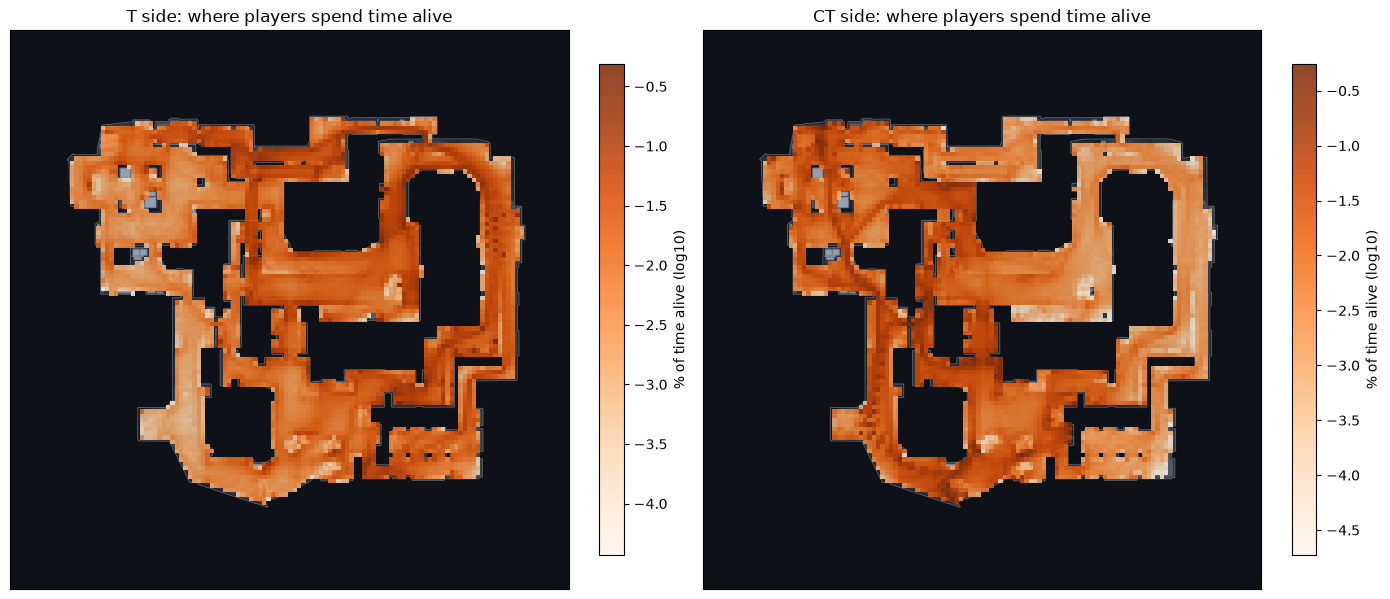

In [9]:
meta = json.load(open("assets/de_mirage_map.json"))
radar = plt.imread("assets/de_mirage_map.png")
xmin, xmax, ymin, ymax = meta["extent"]
BIN = 40

bins = q(f"""
SELECT side, 
        floor(x/ {BIN})::INT AS gx,
        floor(y/ {BIN})::INT AS gy,
        count(*) AS n
FROM player_steps
WHERE is_alive = 1
GROUP BY ALL 
""")

gx0, gy0 = int(np.floor(xmin / BIN)), int(np.floor(ymin / BIN))
nx, ny = int(np.ceil(xmax / BIN)) - gx0, int(np.ceil(ymax / BIN)) - gy0
grid_extent = (gx0 * BIN, (gx0 + nx) * BIN, gy0 * BIN, (gy0 + ny) * BIN)

fig, axes = plt.subplots(1, 2, figsize=(14, 7))
for ax, (side, title) in zip(axes, [("t", "T side"), ("ct", "CT side")]):
    d = bins[bins.side == side]
    grid = np.zeros((ny, nx))
    ix, iy = d.gx.to_numpy() - gx0, d.gy.to_numpy() - gy0
    keep = (ix >= 0) & (ix < nx) & (iy >= 0) & (iy < ny)
    np.add.at(grid, (iy[keep], ix[keep]), d.n.to_numpy()[keep])
    share = grid / grid.sum() * 100  # % of the side's time alive in each cell

    ax.imshow(radar, extent=meta["extent"])
    im = ax.imshow(np.ma.masked_equal(np.log10(share + 1e-6), -6), origin="lower",
                   extent=grid_extent, cmap="Oranges", alpha=0.85)
    ax.set_title(f"{title}: where players spend time alive")
    ax.set_xlim(xmin, xmax); ax.set_ylim(ymin, ymax)
    ax.set_xticks([]); ax.set_yticks([])
    cb = fig.colorbar(im, ax=ax, fraction=0.04)
    cb.set_label("% of time alive (log10)")
plt.tight_layout()
plt.show()

Analysis: 
Each team has a perspective rount or area on the map that players take when they are on either side. As expected, the teams frequent more on the side their team starts on. For example, the Terrorist (T) team tend to spend most of their time on the right side. Similarly, the Counter-Terrorist (CT) tend to roam all over their side of the map.

(Note for more findings analyzing this longer)

# 2: Round Outcome/ economy next


In [10]:
eq = q("""
SELECT t_equip, ct_equip
FROM rounds
WHERE round_num NOT IN (1, 13) -- skip pistol rounds
    AND  t_players = 5 AND ct_players = 5
""")

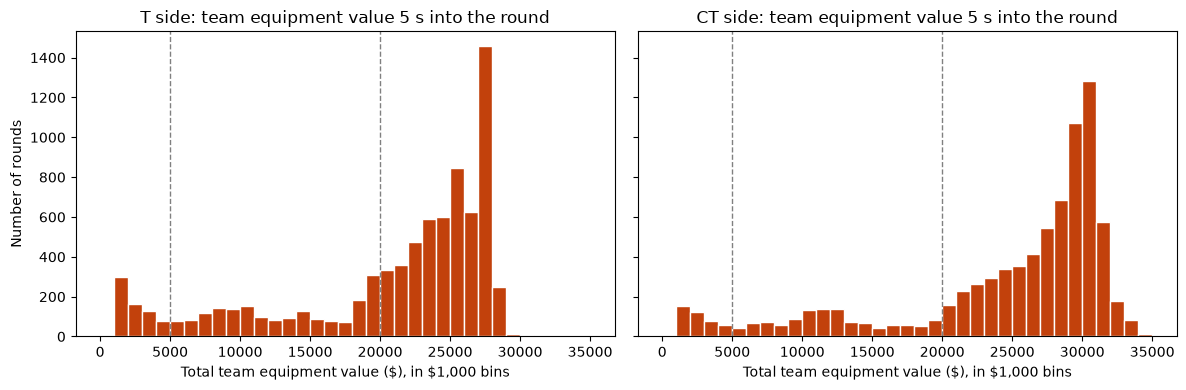

In [15]:
# Histogram: how many rounds had each level of team equipment value, measured 5 s after freeze end.
# Each bar = number of rounds whose team equipment fell in that $1,000 range (pistol rounds excluded).
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, col, title in zip(axes, ["t_equip", "ct_equip"], ["T side", "CT side"]):
    ax.hist(eq[col], bins=np.arange(0, 35001, 1000), color="#c2410c", edgecolor="white")
    for x in (5000, 20000):
        ax.axvline(x, color="gray", ls="--", lw=1)
    ax.set_title(f"{title}: team equipment value 5 s into the round")
    ax.set_xlabel(r"Total team equipment value (\$), in \$1,000 bins")
axes[0].set_ylabel("Number of rounds")
plt.tight_layout()
plt.show()

Analysis: as expected, the more rounds there are in a game, the more likely both sides will have more money. That is why the plot is skewed left. However, the noticible difference between the two sides is CT tends to have more money the more rounds their on whenever they are playing on mirage. CT side has more money reaching over $30,000 in equipment compared to that of the T side where they reach $27,600 worth of equipment. 

This is a little expected due to the T side have cheaper items compared to that of CT side. The assumption can be made that when looking at utility usage, there might be lower expected usage in the CT side than the T side. 